In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_parquet('../test-shop/history.parquet')
df

,article_id,week_start,units,on_hand
0,A100181,2020-07-27,5.0,5.0
1,A100181,2020-08-03,1.0,4.0
2,A100181,2020-08-10,1.0,15.0
3,A100181,2020-08-17,0.0,15.0
4,A100181,2020-08-24,1.0,14.0
...,...,...,...,...
415267,A999951,2023-03-20,0.0,0.0
415268,A999951,2023-03-27,20.0,35.0
415269,A999951,2023-04-03,20.0,15.0
415270,A999951,2023-04-10,0.0,15.0


In [5]:
a_weekly_df = pd.read_parquet('../set-a/weekly.parquet')
a_weekly_df

,store_id,article_id,week_start,units,in_stock
0,0,126,2021-04-12,0.0,True
1,0,126,2021-04-19,0.0,True
2,0,126,2021-04-26,3.0,True
3,0,126,2021-05-03,3.0,True
4,0,126,2021-05-10,0.0,True
...,...,...,...,...,...
98830,66,126,2024-05-06,0.0,True
98831,66,126,2024-05-13,3.0,True
98832,66,126,2024-05-20,0.0,True
98833,66,126,2024-05-27,8.0,True


In [12]:
df['week_start'] = pd.to_datetime(df['week_start'])
df['year'] = df['week_start'].dt.year
df['month'] = df['week_start'].dt.month
df['week'] = df['week_start'].dt.isocalendar().week
df['day_of_week'] = df['week_start'].dt.dayofweek
df.drop(columns=['week_start'], inplace=True)
df

C:\Users\mehme\AppData\Local\Temp\ipykernel_13304\108855297.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['day_of_week'] = df['week_start'].dt.dayofweek
C:\Users\mehme\AppData\Local\Temp\ipykernel_13304\108855297.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['week_start'], inplace=True)


,article_id,units,on_hand,year,month,week,day_of_week
0,A100181,5.0,5.0,2020,7,31,0
1,A100181,1.0,4.0,2020,8,32,0
2,A100181,1.0,15.0,2020,8,33,0
3,A100181,0.0,15.0,2020,8,34,0
4,A100181,1.0,14.0,2020,8,35,0
...,...,...,...,...,...,...,...
415267,A999951,0.0,0.0,2023,3,12,0
415268,A999951,20.0,35.0,2023,3,13,0
415269,A999951,20.0,15.0,2023,4,14,0
415270,A999951,0.0,15.0,2023,4,15,0


In [13]:
a_weekly_df['week_start'] = pd.to_datetime(a_weekly_df['week_start'])
a_weekly_df['year'] = a_weekly_df['week_start'].dt.year
a_weekly_df['month'] = a_weekly_df['week_start'].dt.month
a_weekly_df['week'] = a_weekly_df['week_start'].dt.isocalendar().week
a_weekly_df['day_of_week'] = a_weekly_df['week_start'].dt.dayofweek
a_weekly_df.drop(columns=['week_start'], inplace=True)
a_weekly_df

C:\Users\mehme\AppData\Local\Temp\ipykernel_13304\2885482163.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  a_weekly_df['day_of_week'] = a_weekly_df['week_start'].dt.dayofweek
C:\Users\mehme\AppData\Local\Temp\ipykernel_13304\2885482163.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  a_weekly_df.drop(columns=['week_start'], inplace=True)


,store_id,article_id,units,in_stock,year,month,week,day_of_week
0,0,126,0.0,True,2021,4,15,0
1,0,126,0.0,True,2021,4,16,0
2,0,126,3.0,True,2021,4,17,0
3,0,126,3.0,True,2021,5,18,0
4,0,126,0.0,True,2021,5,19,0
...,...,...,...,...,...,...,...,...
98830,66,126,0.0,True,2024,5,19,0
98831,66,126,3.0,True,2024,5,20,0
98832,66,126,0.0,True,2024,5,21,0
98833,66,126,8.0,True,2024,5,22,0


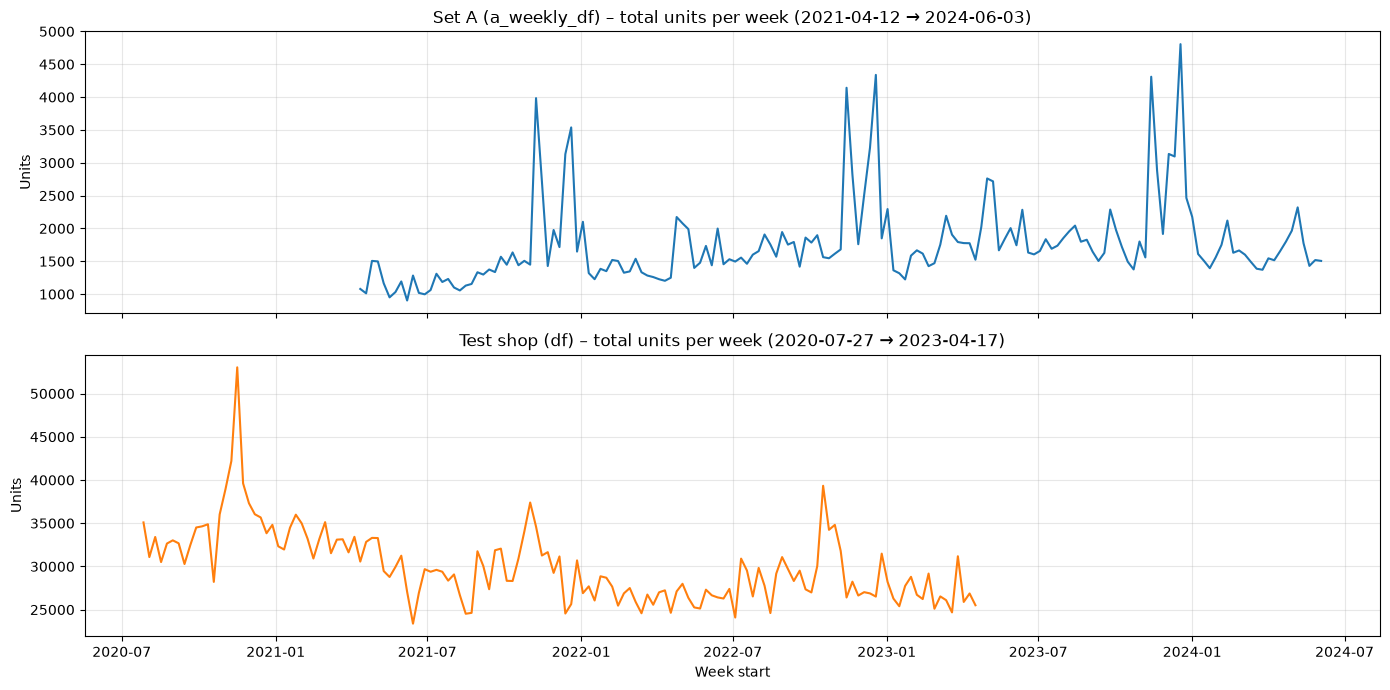

In [14]:
# Total units sold per week: a_weekly_df vs df (test-shop)
# week_start was dropped, so rebuild the week date from year / month / ISO week.
# ISO year can differ from calendar year at year boundaries (e.g. 2024-12-30 is ISO week 1 of 2025).

def weekly_total(d, value_col='units'):
    iso_year = d['year'].astype(int).copy()
    week = d['week'].astype(int)
    month = d['month'].astype(int)
    iso_year[(month == 12) & (week == 1)] += 1
    iso_year[(month == 1) & (week >= 52)] -= 1
    week_start = pd.to_datetime(
        iso_year.astype(str) + '-' + week.astype(str).str.zfill(2) + '-1',
        format='%G-%V-%u'
    )
    return d.groupby(week_start)[value_col].sum().sort_index()

a_tot = weekly_total(a_weekly_df)
df_tot = weekly_total(df)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(a_tot.index, a_tot.values, color='tab:blue', lw=1.5)
axes[0].set_title(f'Set A (a_weekly_df) – total units per week ({a_tot.index.min():%Y-%m-%d} → {a_tot.index.max():%Y-%m-%d})')
axes[0].set_ylabel('Units')
axes[0].grid(alpha=0.3)

axes[1].plot(df_tot.index, df_tot.values, color='tab:orange', lw=1.5)
axes[1].set_title(f'Test shop (df) – total units per week ({df_tot.index.min():%Y-%m-%d} → {df_tot.index.max():%Y-%m-%d})')
axes[1].set_ylabel('Units')
axes[1].set_xlabel('Week start')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
def overlap_report(a_tot, df_tot, horizon=13, max_lag=8, roll=26, min_train_origins=26):
    """Check how well Set A's weekly totals track the test shop's.

    a_tot, df_tot: pd.Series indexed by week_start (Monday), values = total units.
    """
    # ---------- 1. Align on the overlapping weeks ----------
    both = pd.concat({'a': a_tot, 'shop': df_tot}, axis=1, join='inner').sort_index()
    full = pd.date_range(both.index.min(), both.index.max(), freq='W-MON')
    missing = full.difference(both.index)
    print(f"Overlap: {full.min():%Y-%m-%d} -> {full.max():%Y-%m-%d} | "
          f"{len(both)} weeks with data, {len(missing)} missing weeks")
    if len(missing):
        print("  missing:", [f"{d:%Y-%m-%d}" for d in missing[:10]], '...' if len(missing) > 10 else '')
    both = both.reindex(full)  # gaps stay NaN so diffs don't jump over them

    lg = np.log(both.clip(lower=1))

    # ---------- 2. Correlations at different views ----------
    d1 = lg.diff()                                                 # week-over-week change
    dev = lg - lg.rolling(13, center=True, min_periods=7).mean()   # spikes/dips around local trend
    dh = lg.shift(-horizon) - lg                                   # change over next `horizon` weeks

    def corr(x, y):
        m = x.notna() & y.notna()
        return pd.Series({'pearson': x[m].corr(y[m]),
                          'spearman': x[m].corr(y[m], method='spearman'),
                          'n': int(m.sum())})

    table = pd.DataFrame({
        'log level (trend-driven, misleading)': corr(lg.a, lg.shop),
        'weekly log change': corr(d1.a, d1.shop),
        'deviation from 13w trend': corr(dev.a, dev.shop),
        f'{horizon}w log change (overlapping windows)': corr(dh.a, dh.shop),
    }).T
    print("\nCorrelations (Set A vs shop):")
    print(table.round(3).to_string())

    # ---------- 3. Lead/lag ----------
    # k > 0: Set A from k weeks EARLIER vs shop now (A leads shop)
    ccf = pd.Series({k: d1.shop.corr(d1.a.shift(k)) for k in range(-max_lag, max_lag + 1)})
    best = ccf.abs().idxmax()
    print(f"\nBest lag on weekly changes: {best:+d} weeks (corr {ccf[best]:.3f}); lag 0 corr {ccf[0]:.3f}")

    # ---------- 4. Stability over time ----------
    roll_corr = d1.shop.rolling(roll, min_periods=roll // 2).corr(d1.a)

    # ---------- 5. Backtest: does Set A improve a 13-week forecast of the shop total? ----------
    lvl = both.rolling(4, min_periods=3).mean()          # level at forecast origin
    la, ls = np.log(both.a), np.log(both.shop)
    lla, lls = np.log(lvl.a), np.log(lvl.shop)
    n = len(both)
    X = np.full((n, horizon), np.nan)   # Set A movement from origin level, per step
    Y = np.full((n, horizon), np.nan)   # shop movement from origin level, per step
    for k in range(1, horizon + 1):
        X[:, k - 1] = (la.shift(-k) - lla).values
        Y[:, k - 1] = (ls.shift(-k) - lls).values

    rows = []
    for t in range(n):
        end = t - horizon + 1                     # only origins whose window ended by t
        if end <= 0 or np.isnan(X[t]).any() or np.isnan(Y[t]).any():
            continue
        xt, yt = X[:end].ravel(), Y[:end].ravel()
        m = ~np.isnan(xt) & ~np.isnan(yt)
        if m.sum() < min_train_origins * horizon:
            continue
        beta, alpha = np.polyfit(xt[m], yt[m], 1)
        drift = yt[m].mean()

        base = np.exp(lls.iloc[t])
        actual = both.shop.values[t + 1:t + 1 + horizon]
        fc = {
            'naive':        np.full(horizon, base),
            'drift':        base * np.exp(np.full(horizon, drift)),
            'A_fitted':     base * np.exp(alpha + beta * X[t]),
            'A_raw_ratio':  base * np.exp(X[t]),
        }
        row = {'origin': both.index[t], 'alpha': alpha, 'beta': beta, 'actual': actual.sum()}
        row.update({f'err_{name}': np.abs(actual - f).sum() for name, f in fc.items()})
        rows.append(row)

    bt = pd.DataFrame(rows).set_index('origin')
    if len(bt):
        print(f"\nBacktest: {len(bt)} origins, {horizon}-week horizon, beta fitted on past windows only")
        for name in ['naive', 'drift', 'A_fitted', 'A_raw_ratio']:
            print(f"  WAPE {name:12s}: {bt[f'err_{name}'].sum() / bt['actual'].sum():.4f}")
        print(f"  A_fitted beats drift on {(bt.err_A_fitted < bt.err_drift).mean():.0%} of origins")
        print(f"  beta range: {bt.beta.min():.2f} to {bt.beta.max():.2f} (last {bt.beta.iloc[-1]:.2f})")
    else:
        print("\nBacktest: not enough overlap for the chosen horizon/min_train_origins")

    # ---------- 6. What Set A says about the missing window ----------
    origin = df_tot.index.max()
    a_full = a_tot.sort_index()
    a_lvl = a_full.loc[:origin].tail(4).mean()
    future = a_full.loc[origin + pd.Timedelta(days=1):].head(horizon)
    print(f"\nSet A movement over the forecast window (vs its 4-week level before {origin:%Y-%m-%d}):")
    print((future / a_lvl).round(3).rename('A_ratio').to_string())

    # ---------- Plots ----------
    fig, ax = plt.subplots(2, 2, figsize=(14, 8))
    z = (dev - dev.mean()) / dev.std()
    ax[0, 0].plot(z.index, z.a, label='Set A', lw=1.2)
    ax[0, 0].plot(z.index, z.shop, label='Shop', lw=1.2)
    ax[0, 0].set_title('Deviation from 13w trend (z-scored log)')
    ax[0, 0].legend(); ax[0, 0].grid(alpha=0.3)

    ax[0, 1].scatter(d1.a, d1.shop, s=12, alpha=0.6)
    ax[0, 1].set_xlabel('Set A weekly log change'); ax[0, 1].set_ylabel('Shop weekly log change')
    ax[0, 1].set_title(f'Weekly changes (r = {table.iloc[1, 0]:.2f})'); ax[0, 1].grid(alpha=0.3)

    ax[1, 0].bar(ccf.index, ccf.values)
    ax[1, 0].axhline(0, color='k', lw=0.8)
    ax[1, 0].set_title('Cross-correlation of weekly changes (k>0: A leads)')
    ax[1, 0].set_xlabel('lag k (weeks)'); ax[1, 0].grid(alpha=0.3)

    ax[1, 1].plot(roll_corr.index, roll_corr.values)
    ax[1, 1].axhline(0, color='k', lw=0.8)
    ax[1, 1].set_title(f'Rolling {roll}w correlation of weekly changes'); ax[1, 1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return {'aligned': both, 'corr_table': table, 'ccf': ccf,
            'rolling_corr': roll_corr, 'backtest': bt, 'future_ratio': future / a_lvl}


Overlap: 2021-04-12 -> 2023-04-17 | 106 weeks with data, 0 missing weeks

Correlations (Set A vs shop):
                                      pearson  spearman      n
log level (trend-driven, misleading)   -0.044    -0.037  106.0
weekly log change                      -0.246    -0.133  105.0
deviation from 13w trend               -0.153    -0.104  106.0
13w log change (overlapping windows)    0.241     0.259   93.0

Best lag on weekly changes: +0 weeks (corr -0.246); lag 0 corr -0.246

Backtest: 53 origins, 13-week horizon, beta fitted on past windows only
  WAPE naive       : 0.0830
  WAPE drift       : 0.0878
  WAPE A_fitted    : 0.0906
  WAPE A_raw_ratio : 0.2833
  A_fitted beats drift on 49% of origins
  beta range: 0.06 to 0.15 (last 0.06)

Set A movement over the forecast window (vs its 4-week level before 2023-04-17):
2023-04-24    1.179
2023-05-01    1.608
2023-05-08    1.582
2023-05-15    0.971
2023-05-22    1.071
2023-05-29    1.168
2023-06-05    1.016
2023-06-12    1.330
202

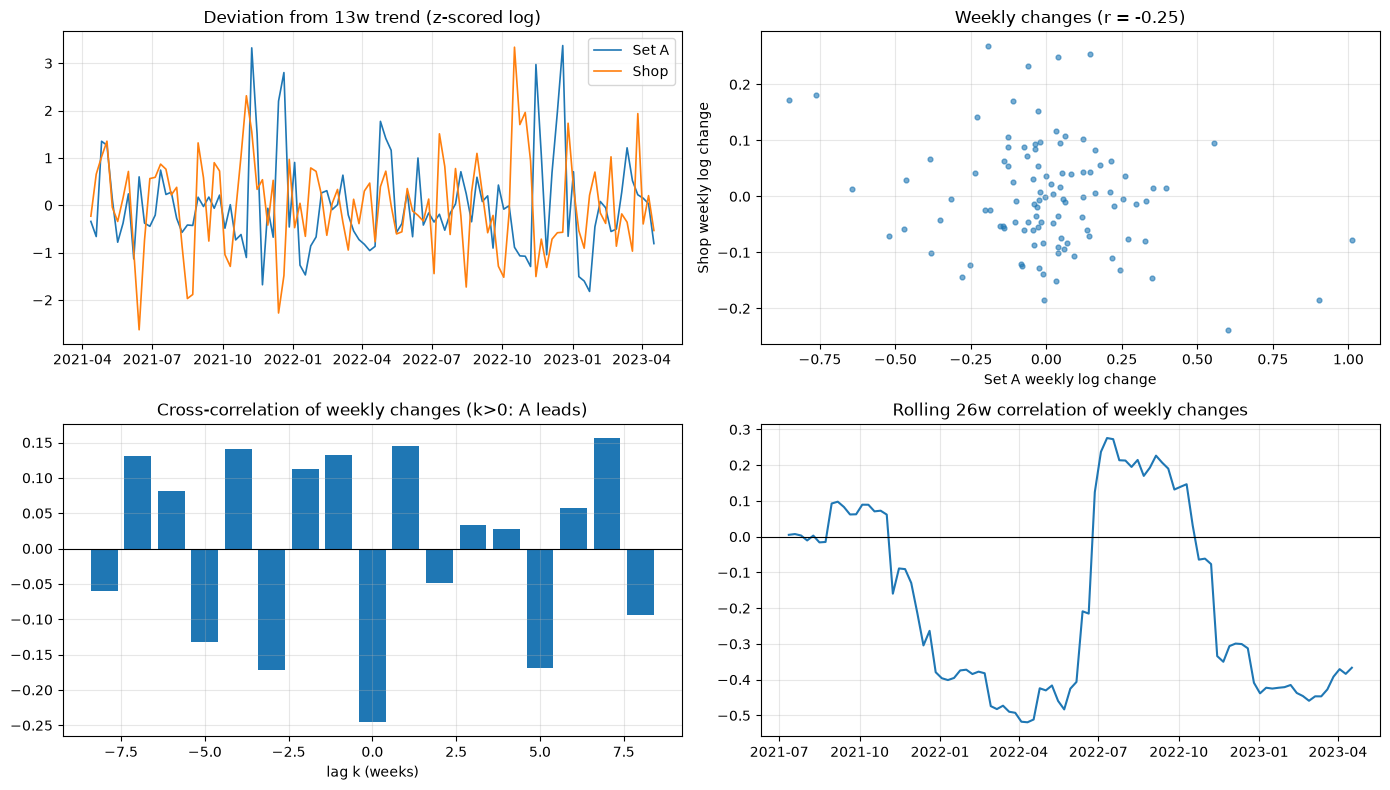

In [17]:
a_tot = weekly_total(a_weekly_df)
df_tot = weekly_total(df)

res = overlap_report(a_tot, df_tot)

In [18]:
def add_week_start(d):
    """Monday of the ISO week, rebuilt from year / month / week."""
    iso_year = d['year'].astype(int).copy()
    week, month = d['week'].astype(int), d['month'].astype(int)
    iso_year[(month == 12) & (week == 1)] += 1
    iso_year[(month == 1) & (week >= 52)] -= 1
    return pd.to_datetime(iso_year.astype(str) + '-' + week.astype(str).str.zfill(2) + '-1',
                          format='%G-%V-%u')


def prep_test(df):
    out = pd.DataFrame({
        'source': 'test',
        'series_id': df['article_id'].astype(str),
        'store_id': 'test_shop',
        'article_id': df['article_id'].astype(str),
        'week_start': add_week_start(df),
        'units': df['units'].astype(float),
        'on_hand': df['on_hand'].astype(float),
        'in_stock': (df['on_hand'] > 0).astype(float),
    })
    return out


def prep_a(a):
    in_stock = a['in_stock'].astype(bool)
    out = pd.DataFrame({
        'source': 'A',
        'series_id': 'A_' + a['store_id'].astype(str) + '_' + a['article_id'].astype(str),
        'store_id': 'A_' + a['store_id'].astype(str),
        'article_id': 'A_' + a['article_id'].astype(str),
        'week_start': add_week_start(a),
        'units': a['units'].astype(float),
        'on_hand': np.where(in_stock, np.nan, 0.0),   # only "out of stock" is known for sure
        'in_stock': in_stock.astype(float),
    })
    return out


def combine(df, a_weekly_df, a_weight=0.3, scale_until=None):
    """Stack test + Set A into one long weekly table.

    a_weight:    sample weight for Set A rows (test rows get 1.0)
    scale_until: only use weeks before this date to compute each series' scale
                 (set it to your backtest cutoff to avoid leakage in validation)
    """
    long = pd.concat([prep_test(df), prep_a(a_weekly_df)], ignore_index=True)

    # Collapse to one row per series per week (no-op if already weekly).
    # in_stock becomes the share of rows in stock that week; on_hand takes the last value.
    long = long.sort_values(['series_id', 'week_start'])
    weekly = (long.groupby(['source', 'series_id', 'store_id', 'article_id', 'week_start'],
                           as_index=False)
                  .agg(units=('units', 'sum'),
                       on_hand=('on_hand', 'last'),
                       in_stock=('in_stock', 'mean')))

    # Per-series scale so big and small sellers are comparable
    base = weekly if scale_until is None else weekly[weekly['week_start'] < pd.Timestamp(scale_until)]
    scale = base.groupby('series_id')['units'].mean()
    weekly['scale'] = weekly['series_id'].map(scale)
    weekly['scale'] = weekly['scale'].where(weekly['scale'] > 0, 1.0).fillna(1.0)
    weekly['units_scaled'] = weekly['units'] / weekly['scale']
    weekly['on_hand_scaled'] = weekly['on_hand'] / weekly['scale']

    weekly['is_test'] = (weekly['source'] == 'test').astype(int)
    weekly['weight'] = np.where(weekly['is_test'] == 1, 1.0, a_weight)

    # Gap report: lag features assume consecutive weeks
    span = weekly.groupby('series_id')['week_start'].agg(['min', 'max', 'count'])
    expected = ((span['max'] - span['min']).dt.days // 7) + 1
    gappy = (expected != span['count'])
    print(f"Rows: {len(weekly):,} | series: {weekly['series_id'].nunique():,} "
          f"(test {weekly.loc[weekly.is_test == 1, 'series_id'].nunique():,}, "
          f"A {weekly.loc[weekly.is_test == 0, 'series_id'].nunique():,})")
    print(f"Series with missing weeks: {gappy.sum():,} "
          f"(test {gappy[~gappy.index.str.startswith('A_')].sum():,}, "
          f"A {gappy[gappy.index.str.startswith('A_')].sum():,})")

    return weekly.sort_values(['series_id', 'week_start']).reset_index(drop=True)

In [19]:
cutoff = pd.Timestamp('2023-01-23')
combined = combine(df, a_weekly_df, scale_until=cutoff)

train = combined[combined.week_start < cutoff]
valid = combined[(combined.week_start >= cutoff) & (combined.is_test == 1)]
# fit on train, predict valid, score against valid.units

Rows: 514,107 | series: 3,503 (test 2,904, A 599)
Series with missing weeks: 0 (test 0, A 0)


In [22]:
train.info()

<class 'pandas.DataFrame'>
Index: 433227 entries, 0 to 514034
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   source          433227 non-null  str           
 1   series_id       433227 non-null  str           
 2   store_id        433227 non-null  str           
 3   article_id      433227 non-null  str           
 4   week_start      433227 non-null  datetime64[us]
 5   units           433227 non-null  float64       
 6   on_hand         329041 non-null  float64       
 7   in_stock        433227 non-null  float64       
 8   scale           433227 non-null  float64       
 9   units_scaled    433227 non-null  float64       
 10  on_hand_scaled  329041 non-null  float64       
 11  is_test         433227 non-null  int64         
 12  weight          433227 non-null  float64       
dtypes: datetime64[us](1), float64(7), int64(1), str(4)
memory usage: 57.1 MB


In [21]:
valid

,source,series_id,store_id,article_id,week_start,units,on_hand,in_stock,scale,units_scaled,on_hand_scaled,is_test,weight
130,test,A100181,test_shop,A100181,2023-01-23,2.0,10.0,1.0,1.176923,1.699346,8.496732,1,1.0
131,test,A100181,test_shop,A100181,2023-01-30,2.0,8.0,1.0,1.176923,1.699346,6.797386,1,1.0
132,test,A100181,test_shop,A100181,2023-02-06,0.0,8.0,1.0,1.176923,0.000000,6.797386,1,1.0
133,test,A100181,test_shop,A100181,2023-02-13,0.0,8.0,1.0,1.176923,0.000000,6.797386,1,1.0
134,test,A100181,test_shop,A100181,2023-02-20,0.0,8.0,1.0,1.176923,0.000000,6.797386,1,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
415267,test,A999951,test_shop,A999951,2023-03-20,0.0,0.0,0.0,1.869231,0.000000,0.000000,1,1.0
415268,test,A999951,test_shop,A999951,2023-03-27,20.0,35.0,1.0,1.869231,10.699588,18.724280,1,1.0
415269,test,A999951,test_shop,A999951,2023-04-03,20.0,15.0,1.0,1.869231,10.699588,8.024691,1,1.0
415270,test,A999951,test_shop,A999951,2023-04-10,0.0,15.0,1.0,1.869231,0.000000,8.024691,1,1.0


In [29]:
# pip install xgboost
from train_gpu import run_backtest

cutoff, inner = '2023-01-23', '2022-10-24'
combined = combine(df, a_weekly_df, scale_until=cutoff)
ds = build_dataset(fill_gaps(combined), a_frac=1.0)
X = feature_cols(ds)

model_l1, s1 = run_backtest(ds, X, cutoff, inner, objective='l1')
model_tw, s2 = run_backtest(ds, X, cutoff, inner, objective='tweedie')

Rows: 514,107 | series: 3,503 (test 2,904, A 599)
Series with missing weeks: 0 (test 0, A 0)
[0]	validation_0-mae:0.54785
[169]	validation_0-mae:0.52485
best trees on inner window: 70


c:\Users\mehme\Desktop\Projects\District19\.venv\Lib\site-packages\xgboost\core.py:569: UserWarning: [23:13:08] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


[l1] cutoff 2023-01-23: model WAPE 0.5254 | naive 0.5615
[0]	validation_0-mae:0.56320
[134]	validation_0-mae:0.54520
best trees on inner window: 35
[tweedie] cutoff 2023-01-23: model WAPE 0.5581 | naive 0.5615


In [30]:
results = []
for a_frac in [0.0, 1.0]:
    for cutoff, inner in [('2022-07-25', '2022-04-25'),
                          ('2022-10-24', '2022-07-25'),
                          ('2023-01-23', '2022-10-24')]:
        ds = build_dataset(fill_gaps(combine(df, a_weekly_df, scale_until=cutoff)), a_frac=a_frac)
        X = feature_cols(ds)
        _, s = run_backtest(ds, X, cutoff, inner, objective='l1')
        results.append((a_frac, cutoff, s))
print(pd.DataFrame(results, columns=['a_frac', 'cutoff', 'wape']).pivot(index='cutoff', columns='a_frac', values='wape'))

Rows: 514,107 | series: 3,503 (test 2,904, A 599)
Series with missing weeks: 0 (test 0, A 0)
[0]	validation_0-mae:0.48186
[200]	validation_0-mae:0.41749
[313]	validation_0-mae:0.41840
best trees on inner window: 214
[l1] cutoff 2022-07-25: model WAPE 0.4814 | naive 0.4962
Rows: 514,107 | series: 3,503 (test 2,904, A 599)
Series with missing weeks: 0 (test 0, A 0)
[0]	validation_0-mae:0.50623
[200]	validation_0-mae:0.45184
[226]	validation_0-mae:0.45204
best trees on inner window: 127
[l1] cutoff 2022-10-24: model WAPE 0.5587 | naive 0.5458
Rows: 514,107 | series: 3,503 (test 2,904, A 599)
Series with missing weeks: 0 (test 0, A 0)
[0]	validation_0-mae:0.54781
[179]	validation_0-mae:0.51722
best trees on inner window: 80
[l1] cutoff 2023-01-23: model WAPE 0.5232 | naive 0.5615
Rows: 514,107 | series: 3,503 (test 2,904, A 599)
Series with missing weeks: 0 (test 0, A 0)
[0]	validation_0-mae:0.48154
[200]	validation_0-mae:0.41810
[201]	validation_0-mae:0.41808
best trees on inner window: 1

In [31]:
pd.Series(model_l1.feature_importances_, index=X).sort_values(ascending=False).head(15)

trend               0.374048
zero_share13        0.162291
mean4               0.081879
ewm4                0.072856
lag0                0.052054
age                 0.036193
mean8               0.020061
mean13              0.018699
woy                 0.016205
std13               0.015794
month               0.015434
mean52              0.014417
log_scale           0.013644
stockout_share13    0.013469
lag52_target        0.011876
dtype: float32

In [ ]:
# MASE-aligned validation + final submission (code in mase_pipeline.py)
# The competition score is per-article MASE averaged UNWEIGHTED, so WAPE (above) is the wrong yardstick:
# it rewards accuracy on best sellers, while the score weighs every article equally.
from mase_pipeline import load_wide, evaluate, median_baseline, quantile_ensemble, make_submission

U, OH = load_wide('../test-shop/history.parquet')
Y = U.values

print('median of last 26 weeks (baseline):')
evaluate(Y, median_baseline, k=26)

print('\nquantile ensemble: mean of q0.45 over last 13 & 26 weeks, 0 after 6 weeks without a sale:')
evaluate(Y, quantile_ensemble)

F = quantile_ensemble(Y)   # forecast 2023-04-24 .. 2023-07-17 from the full history
sub = make_submission(U.index, F, '../submissions/submission_quantile_ensemble_q45.csv')
sub.head()